# Euler explícito: sistema de Lorenz

**Objetivo:** explorar una simulación no lineal tridimensional y reconocer los
límites de la comparación a largo plazo.

$$\dot x=\sigma(y-x),\quad \dot y=x(\rho-z)-y,\quad
\dot z=xy-\beta z.$$

Usamos $\sigma=10$, $\rho=28$, $\beta=8/3$, $h=0.005$ e inicio $(1,1,1)$.
Euler aproxima cada paso con la pendiente al comienzo del intervalo.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from sistemas_dinamicos import graficar, integrar

sigma, rho, beta = 10.0, 28.0, 8/3
def f(t, s):
    x, y, z = s
    return np.array([sigma*(y-x), x*(rho-z)-y, x*y-beta*z])

h = 0.005
t = np.linspace(0, 40, round(40/h)+1)
estados = integrar(f, t, [1, 1, 1], metodo="euler")
a = np.sqrt(beta*(rho-1))
print("Proyecciones de equilibrios (x, z):", (0, 0), (-a, rho-1), (a, rho-1))

Proyecciones de equilibrios (x, z): (0, 0) (np.float64(-8.48528137423857), 27.0) (np.float64(8.48528137423857), 27.0)


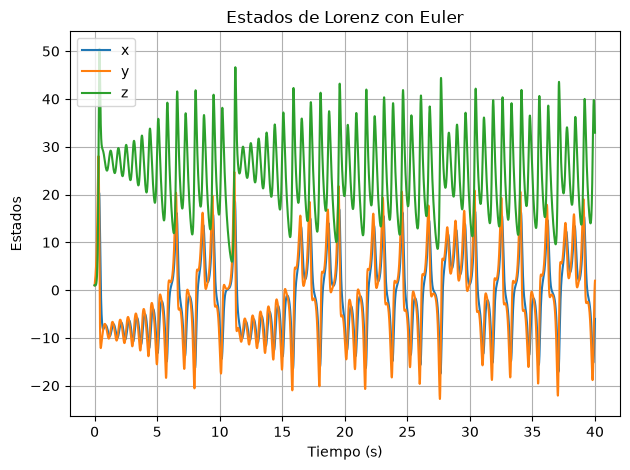

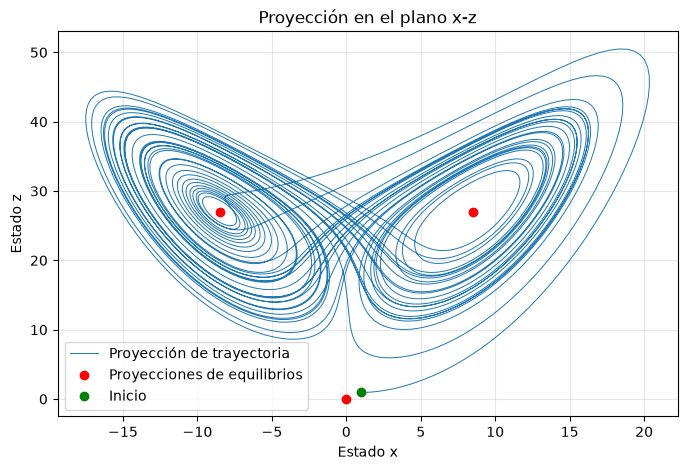

In [2]:
graficar(t, {"x": estados[:, 0], "y": estados[:, 1], "z": estados[:, 2]},
         titulo="Estados de Lorenz con Euler", ylabel="Estados");
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(estados[:, 0], estados[:, 2], lw=0.7, label="Proyección de trayectoria")
ax.plot([0, -a, a], [0, rho-1, rho-1], "ro", label="Proyecciones de equilibrios")
ax.plot(estados[0, 0], estados[0, 2], "go", label="Inicio")
ax.set(xlabel="Estado x", ylabel="Estado z", title="Proyección en el plano x-z")
ax.grid(True, alpha=0.3)
ax.legend();


## Sensibilidad y comparación

Lorenz es sensible a condiciones iniciales y errores numéricos: trayectorias
calculadas con pasos distintos pueden separarse a largo plazo aunque sus
características generales se parezcan. Compara la solución solo en un horizonte
corto y evita interpretar coincidencia visual como garantía de exactitud.

Diferencia máxima de estados en [0, 2]: 5.6886950364595865


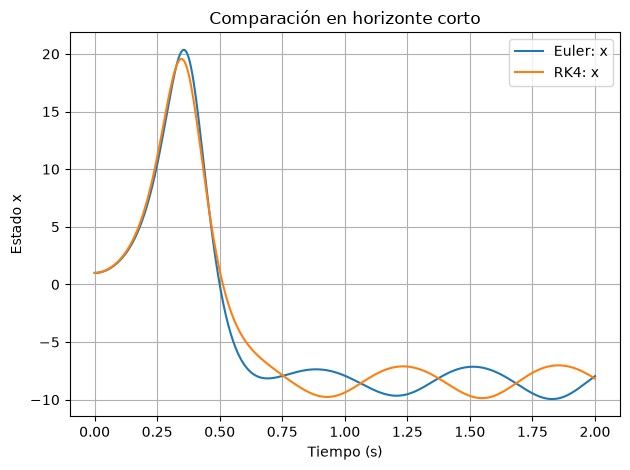

In [3]:
t_corto = np.linspace(0, 2, 401)
euler = integrar(f, t_corto, [1, 1, 1], metodo="euler")
rk4 = integrar(f, t_corto, [1, 1, 1], metodo="rk4")
print("Diferencia máxima de estados en [0, 2]:",
      np.max(np.linalg.norm(euler-rk4, axis=1)))
graficar(t_corto, {"Euler: x": euler[:, 0], "RK4: x": rk4[:, 0]},
         titulo="Comparación en horizonte corto", ylabel="Estado x");

**Practica:** compara $h=0.005$ y $h=0.0025$ en el mismo horizonte
corto; después aumenta el horizonte y observa cuándo dejan de coincidir.
El retrato proyectado no identifica por sí solo todos los detalles en 3D.